# Visualisation Tools for ECG Signals

In this notebook, I developed a series of tools for visualising ECG signals. 

#### Functions
**plot_signal(signal_number)**: Plots a single signal in full. 

**plot_signal_with_peaks(signal_number, cutoff)**: Plots a single signal with peaks above the cutoff label. 

**plot_signal_with_troughs(signal_number, cutoff)**: Plots a single signal with troughs in magnitude larger than the cutoff labeled. 

**plot_segment(signal_number, t1, t2)**: Plot a segment of a single signal ranging from t1 to t2. 

### Using WFDB to Read Signal Data
The documentation for WFDB is available here: https://wfdb.readthedocs.io/en/latest/

In [5]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

#### Plotting each Signal in a Directory
Press enter to create the plot of each sequential signal in the directory.  

In [ ]:
wfdb.plot.plot_all_records('physionet2017/training2017')

#### Plotting an Individual Signal

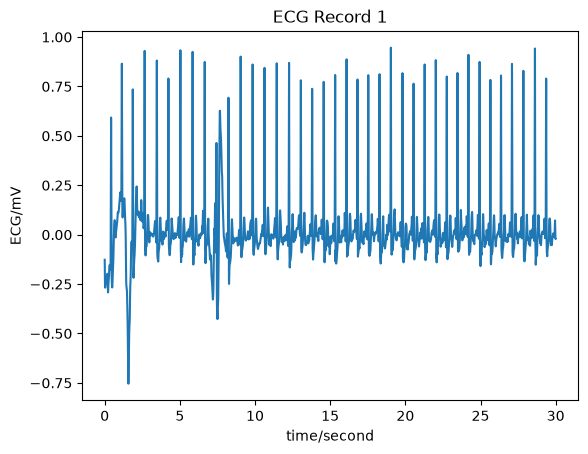

In [10]:
def plot_signal(signal_number):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    wfdb.plot_wfdb(record=record,  
                   title=f'ECG Record {signal_number}', 
                   time_units='seconds')

plot_signal(1)

#### Annotating an ECG Plot - Peaks

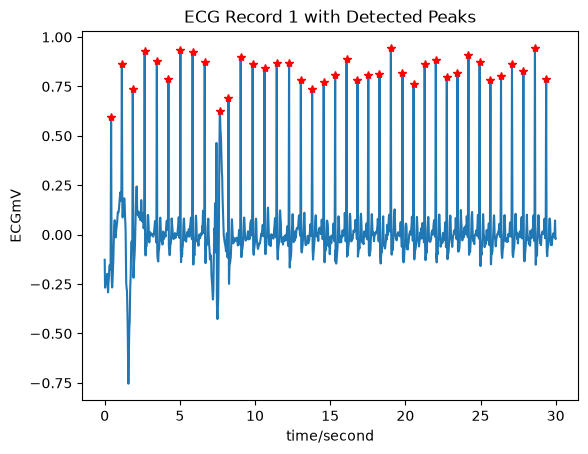

In [11]:
def plot_signal_with_peaks(signal_number, cutoff):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    sig = record.p_signal[:, 0]  # Get the first channel of the signal
    peaks, _ = find_peaks(record.p_signal[:, 0], height=cutoff, distance=100)

    ann = wfdb.Annotation(record_name=f'physionet2017/training2017/A{signal_number:05d}',
                      extension='qrs', 
                      sample=peaks,
                      symbol=['N'] * len(peaks),
                      chan=np.zeros(len(peaks), dtype=int),
                      fs=record.fs)

    wfdb.plot_wfdb(record=record, annotation=ann, title=f'ECG Record {signal_number} with Detected Peaks', time_units='seconds')

plot_signal_with_peaks(1, cutoff=0.5)

#### Annotating an ECG Plot - Troughs

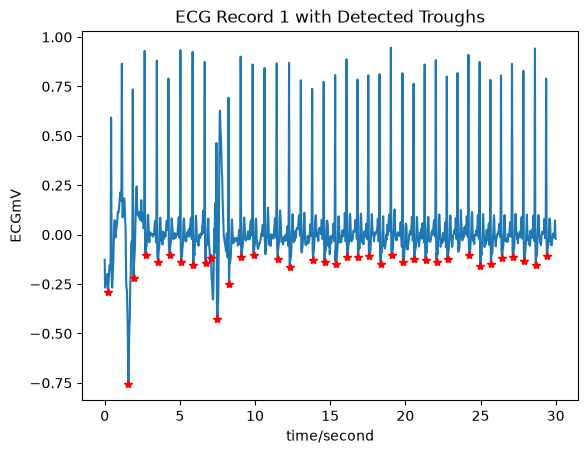

In [12]:
def plot_signal_with_troughs(signal_number, cutoff):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    sig = record.p_signal[:, 0]  # Get the first channel of the signal
    troughs, _ = find_peaks(-record.p_signal[:, 0], height=cutoff, distance=100)

    ann = wfdb.Annotation(record_name=f'physionet2017/training2017/A{signal_number:05d}',
                      extension='qrs', 
                      sample=troughs,
                      symbol=['N'] * len(troughs),
                      chan=np.zeros(len(troughs), dtype=int),
                      fs=record.fs)

    wfdb.plot_wfdb(record=record, annotation=ann, title=f'ECG Record {signal_number} with Detected Troughs', time_units='seconds')

plot_signal_with_troughs(1, cutoff=0.1)

#### Plot a Segment of the Signal

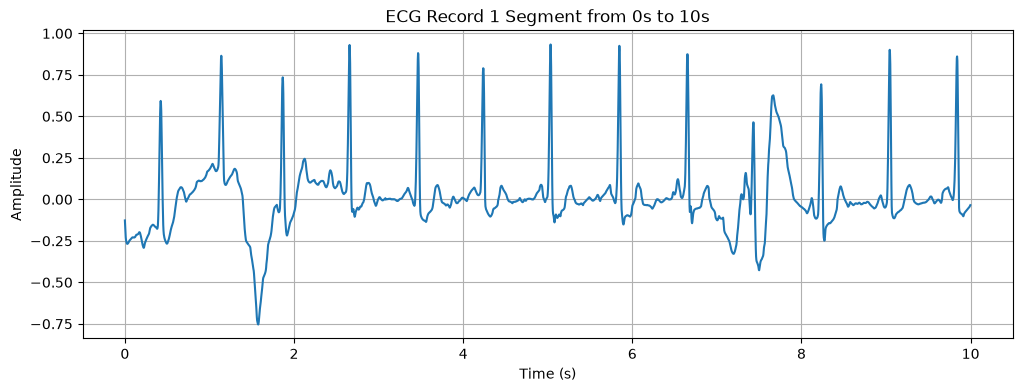

In [21]:
def segment_signal(signal_number, start_time, end_time):
    record = wfdb.rdheader(f'physionet2017/training2017/A{signal_number:05d}') # Read the record header
    segment = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}', sampfrom=int(start_time * record.fs), sampto=int(end_time * record.fs)) # Read the record segment
    return record, segment

def plot_segment(signal_number, start_time, end_time): # Plot a segment of a complete record
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    start_sample = int(start_time * record.fs)
    end_sample = int(end_time * record.fs)

    segment = record.p_signal[start_sample:end_sample, 0]  # Get the first channel of the signal

    plt.figure(figsize=(12, 4))
    plt.plot(np.arange(start_sample, end_sample) / record.fs, segment)
    plt.title(f'ECG Record {signal_number} Segment from {start_time}s to {end_time}s')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.grid()
    plt.show()

plot_segment(1, start_time=0, end_time=10)

## To Do - NO CLAUDE

#### **Peak to Peak Region**
Develop code which allows you to zoom in on a single pulse. 

#### **QRS Detection**
The first step is to create some code which can detect the various points of the sinus rhythm. This will require peak and trough detection relative to the previous point. 

#### **Frequency Domain Analysis**
Look into how to extract the frequency spectrum from the training samples. 